# Implementation 2: Choosing the Relaxation Parameter $\omega$

**Math 455 Midterm Project: Relaxation Methods**

Implementation 1 built Algorithm 7.3 (SOR) and checked it against Example 1. This notebook studies the
question SOR leaves open: **which $\omega$ to use**. It

1. adds the Jacobi method, so SOR can be compared with both methods from class;
2. builds the iteration matrices $T_J$, $T_G$ and $T_\omega$ and checks them against the algorithms;
3. checks the SOR code against the textbook's answer key;
4. checks Theorems 7.24–7.26 numerically on Example 1 and the Homework 3 systems;
5. sweeps $\omega$ and saves three figures for the report to `figures/`.

Reference: Burden, Faires & Burden, *Numerical Analysis*, 10th ed., Section 7.4.

In [1]:
import contextlib
import io
import os
from collections import namedtuple

import matplotlib.pyplot as plt
import numpy as np

os.makedirs("figures", exist_ok=True)

## The methods

`sor` is copied unchanged from Implementation 1. With $\omega = 1$ it is Gauss-Seidel.

`jacobi` follows the component form in the Homework 3 notes (§5.9): every new component is built only from
the previous iterate. It uses the same stopping rule as `sor` and returns the same fields.

In [2]:
SORResult = namedtuple("SORResult", ["x", "iterations", "converged", "history"])


def sor(A, b, x0, omega, tol, max_iter, norm=np.inf):
    '''Solve Ax = b by SOR (Burden, Faires & Burden, Algorithm 7.3).

    Returns SORResult(x, iterations, converged, history), where history[k] is
    the iterate x^(k) and history[0] is x0.
    '''
    A = np.asarray(A, dtype=float)
    b = np.asarray(b, dtype=float)
    XO = np.array(x0, dtype=float)
    n = len(b)

    if np.any(np.diag(A) == 0):
        raise ValueError("SOR requires every diagonal entry a_ii to be nonzero")

    x = np.zeros(n)
    history = [XO.copy()]

    k = 1                                                     # Step 1
    while k <= max_iter:                                      # Step 2
        for i in range(n):                                    # Step 3
            x[i] = (1 - omega) * XO[i] + (1 / A[i, i]) * (
                omega * (-A[i, :i] @ x[:i] - A[i, i + 1:] @ XO[i + 1:] + b[i])
            )
        history.append(x.copy())

        if np.linalg.norm(x - XO, norm) < tol:                # Step 4
            return SORResult(x.copy(), k, True, history)

        k += 1                                                # Step 5
        XO = x.copy()                                         # Step 6

    print("Maximum number of iterations exceeded")            # Step 7
    return SORResult(x.copy(), max_iter, False, history)

In [3]:
def jacobi(A, b, x0, tol, max_iter, norm=np.inf):
    '''Solve Ax = b by the Jacobi method. Returns the same fields as sor().'''
    A = np.asarray(A, dtype=float)
    b = np.asarray(b, dtype=float)
    XO = np.array(x0, dtype=float)
    n = len(b)

    if np.any(np.diag(A) == 0):
        raise ValueError("Jacobi requires every diagonal entry a_ii to be nonzero")

    history = [XO.copy()]
    for k in range(1, max_iter + 1):
        x = np.array([(b[i] - A[i, :i] @ XO[:i] - A[i, i + 1:] @ XO[i + 1:]) / A[i, i]
                      for i in range(n)])
        history.append(x.copy())
        if np.linalg.norm(x - XO, norm) < tol:
            return SORResult(x, k, True, history)
        XO = x

    print("Maximum number of iterations exceeded")
    return SORResult(x, max_iter, False, history)

## Iteration matrices

Each method can be written as $\mathbf{x}^{(k)} = T\mathbf{x}^{(k-1)} + \mathbf{c}$. Using the class convention
$A = D + L + U$ (diagonal, strictly lower and strictly upper parts):

$$T_J = -D^{-1}(L+U), \qquad T_\omega = (D + \omega L)^{-1}\big[(1-\omega)D - \omega U\big], \qquad
\mathbf{c}_\omega = \omega(D + \omega L)^{-1}\mathbf{b},$$

and $T_G = T_1 = -(D+L)^{-1}U$. The textbook writes $A = D - L - U$, so Eq. (7.18) has the opposite signs on
$L$ and $U$; it is the same matrix.

The iteration converges from every starting vector if and only if the spectral radius $\rho(T) < 1$, and the
error shrinks by roughly a factor of $\rho(T)$ per iteration (Homework 3 notes, §5.6).

In [4]:
def split(A):
    '''Return D, L, U with A = D + L + U (class convention).'''
    A = np.asarray(A, dtype=float)
    return np.diag(np.diag(A)), np.tril(A, -1), np.triu(A, 1)


def jacobi_matrix(A):
    D, L, U = split(A)
    return -np.linalg.solve(D, L + U)


def sor_matrix(A, omega):
    D, L, U = split(A)
    return np.linalg.solve(D + omega * L, (1 - omega) * D - omega * U)


def sor_vector(A, b, omega):
    D, L, U = split(A)
    return omega * np.linalg.solve(D + omega * L, np.asarray(b, dtype=float))


def spectral_radius(T):
    return np.max(np.abs(np.linalg.eigvals(T)))


def optimal_omega(A):
    '''Theorem 7.26: optimal omega for a positive definite tridiagonal matrix.'''
    return 2 / (1 + np.sqrt(1 - spectral_radius(jacobi_matrix(A)) ** 2))

## Test systems

* **Example 1** (p. 471), positive definite and tridiagonal. Its matrix is also the one in Example 2.
* **Homework 3, problems 12–15.** Problem 12(b) is also textbook Exercise 7.4 #1(b), which has a published
  answer. Problems 14 and 15 are the cases where Jacobi or Gauss-Seidel fails.

Problems 12(a) and 12(b) give no exact solution, so their reference solution comes from `np.linalg.solve`.

In [5]:
System = namedtuple("System", ["name", "A", "b", "x0", "exact"])


def make_system(name, A, b, x0, exact=None):
    A = np.array(A, dtype=float)
    b = np.array(b, dtype=float)
    exact = np.linalg.solve(A, b) if exact is None else np.array(exact, dtype=float)
    return System(name, A, b, np.array(x0, dtype=float), exact)


EX1 = make_system("Example 1", [[4, 3, 0], [3, 4, -1], [0, -1, 4]], [24, 30, -24], [1, 1, 1], [3, 4, -5])
HW3 = [
    make_system("HW3 #12(a)", [[3, -1, 1], [3, 6, 2], [3, 3, 7]], [1, 0, 7], [0, 0, 0]),
    make_system("HW3 #12(b)", [[10, -1, 0], [-1, 10, -2], [0, -2, 10]], [9, 7, 6], [0, 0, 0]),
    make_system("HW3 #14", [[2, -1, 1], [2, 2, 2], [-1, -1, 2]], [-1, 4, -5], [0, 0, 0], [1, 2, -1]),
    make_system("HW3 #15", [[1, 2, -2], [1, 1, 1], [2, 2, 1]], [7, 2, 5], [0, 0, 0], [1, 2, -1]),
]

for s in [EX1] + HW3:
    assert np.allclose(s.A @ s.exact, s.b), s.name
print("All systems set up; each reference solution satisfies Ax = b")

All systems set up; each reference solution satisfies Ax = b


## Test 1: Jacobi and Gauss-Seidel reproduce the Homework 3 notes

The notes (§5.8) work two Jacobi steps by hand on $3x - y = 5$, $-x + 2y = 4$ from $\mathbf{x}_0 = \mathbf{0}$,
getting $\mathbf{x}_1 = (5/3, 2)$ and $\mathbf{x}_2 = (7/3, 17/6)$. They also take one Gauss-Seidel step,
getting $(5/3, 17/6)$.

In [6]:
A_notes, b_notes = [[3, -1], [-1, 2]], [5, 4]

jac = jacobi(A_notes, b_notes, [0, 0], tol=1e-12, max_iter=100)
gs = sor(A_notes, b_notes, [0, 0], omega=1.0, tol=1e-12, max_iter=100)

assert np.allclose(jac.history[1], [5 / 3, 2], atol=1e-12)
assert np.allclose(jac.history[2], [7 / 3, 17 / 6], atol=1e-12)
assert np.allclose(gs.history[1], [5 / 3, 17 / 6], atol=1e-12)
assert np.allclose(jac.x, [14 / 5, 17 / 5]) and np.allclose(gs.x, [14 / 5, 17 / 5])
print("PASS: matches the hand computations in the notes, and both converge to (14/5, 17/5)")

PASS: matches the hand computations in the notes, and both converge to (14/5, 17/5)


## Test 2: The iteration matrices describe the algorithms

The spectral radius results below are about $T_J$ and $T_\omega$, so these matrices must reproduce the
algorithms. One step of `jacobi` from a random vector must equal $T_J\mathbf{x} + D^{-1}\mathbf{b}$, and one
step of `sor` must equal $T_\omega\mathbf{x} + \mathbf{c}_\omega$.

In [7]:
rng = np.random.default_rng(455)
for s in [EX1] + HW3:
    D, _, _ = split(s.A)
    for _ in range(5):
        x = rng.normal(size=3)
        one_step = jacobi(s.A, s.b, x, tol=np.inf, max_iter=1).x
        assert np.allclose(one_step, jacobi_matrix(s.A) @ x + np.linalg.solve(D, s.b), atol=1e-12)
        for omega in [0.3, 1.0, 1.25, 1.9]:
            one_step = sor(s.A, s.b, x, omega=omega, tol=np.inf, max_iter=1).x
            assert np.allclose(one_step, sor_matrix(s.A, omega) @ x + sor_vector(s.A, s.b, omega), atol=1e-12)
print("PASS: T_J and T_omega reproduce one step of each algorithm on all five systems")

PASS: T_J and T_omega reproduce one step of each algorithm on all five systems


## Test 3: The textbook's answer key

Exercise 7.4 #1(b) uses the same system as Homework 3 #12(b). The answers on p. 847 of the textbook give:

| Exercise | Task | Published answer |
|---|---|---|
| 1(b) | two SOR iterations, $\omega = 1.1$ | $(0.9876790, 0.9784935, 0.7899328)^t$ |
| 3(b) | two SOR iterations, $\omega = 1.3$ | $(0.957073, 0.9903875, 0.7206569)^t$ |
| 5(b) | $\omega = 1.2$, $TOL = 10^{-3}$, $l_\infty$ | $\mathbf{x}^{(7)} = (0.9958341, 0.9579041, 0.7915756)^t$ |
| 7(b) | optimal $\omega = 1.012823$, same stopping rule | $\mathbf{x}^{(4)} = (0.9957846, 0.9578935, 0.7915788)^t$ |

The last two rows also check Algorithm 7.3's stopping rule and the Theorem 7.26 formula. Each answer is
compared to within half a unit in its last printed digit.

In [8]:
s = HW3[1]

two_steps_11 = sor(s.A, s.b, s.x0, omega=1.1, tol=0, max_iter=2)
two_steps_13 = sor(s.A, s.b, s.x0, omega=1.3, tol=0, max_iter=2)
ex5 = sor(s.A, s.b, s.x0, omega=1.2, tol=1e-3, max_iter=100)
omega_7 = optimal_omega(s.A)
ex7 = sor(s.A, s.b, s.x0, omega=omega_7, tol=1e-3, max_iter=100)

assert np.allclose(two_steps_11.x, [0.9876790, 0.9784935, 0.7899328], atol=0.5e-7)
assert np.allclose(two_steps_13.x, [0.957073, 0.9903875, 0.7206569], atol=0.5e-6)
assert ex5.iterations == 7 and np.allclose(ex5.x, [0.9958341, 0.9579041, 0.7915756], atol=0.5e-7)
assert abs(omega_7 - 1.012823) < 0.5e-6
assert ex7.iterations == 4 and np.allclose(ex7.x, [0.9957846, 0.9578935, 0.7915788], atol=0.5e-7)

print(f"Optimal omega from Theorem 7.26: {omega_7:.6f} (book: 1.012823)")
print("PASS: all four answers match the textbook")

Maximum number of iterations exceeded
Maximum number of iterations exceeded
Optimal omega from Theorem 7.26: 1.012823 (book: 1.012823)
PASS: all four answers match the textbook


The two "Maximum number of iterations exceeded" messages above are expected: Exercises 1 and 3 ask for exactly
two iterations, so those runs are given $N = 2$ and $TOL = 0$.

## Spectral radius against $\omega$

From here on, every system is evaluated on a grid of $\omega$ values across $(0, 2)$.

In [9]:
OMEGAS = np.round(np.arange(0.02, 1.99, 0.01), 2)


def rho_curve(A):
    return np.array([spectral_radius(sor_matrix(A, w)) for w in OMEGAS])


RHO = {s.name: rho_curve(s.A) for s in [EX1] + HW3}

# A finer grid, used to locate the best omega and the edge of convergence more precisely
FINE = np.round(np.arange(0.001, 2.0, 0.001), 3)
FINE_RHO = {s.name: np.array([spectral_radius(sor_matrix(s.A, w)) for w in FINE]) for s in [EX1] + HW3}


def best_omega(name):
    '''The omega with the smallest spectral radius on the fine grid, and that radius.'''
    i = np.argmin(FINE_RHO[name])
    return FINE[i], FINE_RHO[name][i]

## Test 4: Theorems 7.24–7.26

* **Theorem 7.24 (Kahan):** if every $a_{ii} \neq 0$, then $\rho(T_\omega) \ge |\omega - 1|$. So SOR can only
  converge for $0 < \omega < 2$. This must hold for **every** system.
* **Theorem 7.25 (Ostrowski–Reich):** if $A$ is positive definite and $0 < \omega < 2$, SOR converges. Example 1
  and HW3 #12(b) are positive definite, so $\rho(T_\omega) < 1$ across the whole grid.
* **Theorem 7.26:** if $A$ is also tridiagonal, then $\rho(T_G) = \rho(T_J)^2$, the optimal $\omega$ is
  $2/\big(1 + \sqrt{1 - \rho(T_J)^2}\big)$, and $\rho(T_\omega) = \omega - 1$ at that $\omega$.

The same functions also confirm the spectral radii that Homework 3 #14 and #15 ask you to show.

In [10]:
def is_positive_definite(A):
    return np.allclose(A, A.T) and np.all(np.linalg.eigvalsh(A) > 0)


# Theorem 7.24 (Kahan), for every system
for s in [EX1] + HW3:
    assert np.all(RHO[s.name] >= np.abs(OMEGAS - 1) - 1e-9), s.name

# Theorems 7.25 and 7.26, for the positive definite tridiagonal systems
for s in [EX1, HW3[1]]:
    assert is_positive_definite(s.A)
    assert np.all(RHO[s.name] < 1)
    rho_j = spectral_radius(jacobi_matrix(s.A))
    rho_g = spectral_radius(sor_matrix(s.A, 1.0))
    w_opt = optimal_omega(s.A)
    assert abs(rho_g - rho_j ** 2) < 1e-12
    assert abs(spectral_radius(sor_matrix(s.A, w_opt)) - (w_opt - 1)) < 1e-6
    assert abs(best_omega(s.name)[0] - w_opt) <= 0.001  # fine-grid spacing
    print(f"{s.name}: rho(T_J) = {rho_j:.4f}, rho(T_G) = {rho_g:.4f}, optimal omega = {w_opt:.4f}, "
          f"rho(T_opt) = {w_opt - 1:.4f}")

# Example 2: rho(T_J) = sqrt(0.625), optimal omega about 1.24
assert abs(spectral_radius(jacobi_matrix(EX1.A)) - np.sqrt(0.625)) < 1e-12
assert round(optimal_omega(EX1.A), 2) == 1.24

# Homework 3 #14 and #15, parts (a) and (c)
A14, A15 = HW3[2].A, HW3[3].A
assert abs(spectral_radius(jacobi_matrix(A14)) - np.sqrt(5) / 2) < 1e-12
assert abs(spectral_radius(sor_matrix(A14, 1.0)) - 1 / 2) < 1e-12
# rho(T_J) = 0 for #15: T_J is nilpotent (T_J^3 = 0). Checked directly, because eigvals() of a
# nilpotent matrix is only accurate to about 1e-5.
assert np.allclose(np.linalg.matrix_power(jacobi_matrix(A15), 3), 0, atol=1e-12)
assert abs(spectral_radius(sor_matrix(A15, 1.0)) - 2) < 1e-12

print("PASS: Theorems 7.24-7.26, Example 2, and HW3 #14-15 (a), (c) all check out")

Example 1: rho(T_J) = 0.7906, rho(T_G) = 0.6250, optimal omega = 1.2404, rho(T_opt) = 0.2404
HW3 #12(b): rho(T_J) = 0.2236, rho(T_G) = 0.0500, optimal omega = 1.0128, rho(T_opt) = 0.0128
PASS: Theorems 7.24-7.26, Example 2, and HW3 #14-15 (a), (c) all check out


## Iteration counts against $\omega$

The spectral radius predicts the convergence rate; the iteration count is what you actually pay. As in
Implementation 1, "accurate" means $\|\mathbf{x}^{(k)} - \mathbf{x}\|_\infty < 0.5 \times 10^{-7}$ (seven decimal places),
the measure behind the book's 34 and 14. A run that never gets there within 3000 iterations, including every
divergent run, counts as `None`.

In [11]:
MAX_ITER = 3000


def first_accurate(history, exact, threshold=0.5e-7):
    '''First k whose true error ||x^(k) - exact||_inf is below threshold, or None.'''
    for k, x in enumerate(history):
        if np.linalg.norm(x - exact, np.inf) < threshold:
            return k
    return None


def iterations_needed(s, omega=None):
    '''Iterations to 7 decimal places: SOR with this omega, or Jacobi when omega is None.'''
    # Divergent runs overflow and print Step 7's message; neither matters here, as the count is None either way.
    with np.errstate(over="ignore", invalid="ignore"), contextlib.redirect_stdout(io.StringIO()):
        if omega is None:
            result = jacobi(s.A, s.b, s.x0, tol=1e-12, max_iter=MAX_ITER)
        else:
            result = sor(s.A, s.b, s.x0, omega=omega, tol=1e-12, max_iter=MAX_ITER)
    return first_accurate(result.history, s.exact)


EX1_ITERS = [iterations_needed(EX1, w) for w in OMEGAS]

best = min((n, w) for n, w in zip(EX1_ITERS, OMEGAS) if n is not None)
print(f"Example 1: Gauss-Seidel {iterations_needed(EX1, 1.0)}, SOR(1.25) {iterations_needed(EX1, 1.25)}, "
      f"Jacobi {iterations_needed(EX1)}")
print(f"Fewest iterations on the grid: {best[0]} at omega = {best[1]}")

assert iterations_needed(EX1, 1.0) == 34 and iterations_needed(EX1, 1.25) == 14
print("PASS: the sweep agrees with the book's 34 and 14")

Example 1: Gauss-Seidel 34, SOR(1.25) 14, Jacobi 78
Fewest iterations on the grid: 14 at omega = 1.22
PASS: the sweep agrees with the book's 34 and 14


## Summary for the Homework 3 systems

For each system: the spectral radius for Jacobi and Gauss-Seidel, the best $\omega$ (to 0.001), the range of
$\omega$ where SOR converges, and the iterations each method needs.

In [12]:
def converging_range(name):
    ok = FINE[FINE_RHO[name] < 1]
    if len(ok) == len(FINE):
        return "all of (0, 2)"
    return f"{ok.min():.3f} to {ok.max():.3f}" if len(ok) else "none"


def fmt_iters(n):
    return "diverges" if n is None else str(n)


SUMMARY = []  # rows used again by Figure 2
print(f"{'system':<12}{'rho_J':>7}{'rho_G':>7}{'best w':>8}{'rho_best':>9}  {'SOR converges for w in':<23}"
      f"{'Jacobi':>9}{'G-S':>9}{'SOR best':>9}")
for s in [EX1] + HW3:
    w_best, rho_best = best_omega(s.name)
    row = dict(name=s.name, w_best=w_best, rho_best=rho_best,
               iters=(iterations_needed(s), iterations_needed(s, 1.0), iterations_needed(s, w_best)))
    SUMMARY.append(row)
    print(f"{s.name:<12}{spectral_radius(jacobi_matrix(s.A)):>7.3f}{spectral_radius(sor_matrix(s.A, 1)):>7.3f}"
          f"{w_best:>8.3f}{rho_best:>9.3f}  {converging_range(s.name):<23}"
          + "".join(f"{fmt_iters(n):>9}" for n in row["iters"]))

system        rho_J  rho_G  best w rho_best  SOR converges for w in    Jacobi      G-S SOR best
Example 1     0.791  0.625   1.241    0.241  all of (0, 2)                 78       34       15
HW3 #12(a)    0.419  0.243   1.016    0.226  0.001 to 1.416                20       13       12
HW3 #12(b)    0.224  0.050   1.013    0.013  all of (0, 2)                 12        7        6
HW3 #14       1.118  0.500   0.835    0.310  0.001 to 1.123          diverges       30       16
HW3 #15       0.000  2.000   0.250    0.919  0.001 to 0.487                 3 diverges      212


What the table shows:

* **Example 1 and #12(b)** are positive definite, so SOR converges for every $\omega$ in the grid (Theorem
  7.25). Their best $\omega$ agrees with Theorem 7.26.
* **#12(a)** is not positive definite. SOR stops converging above $\omega \approx 1.42$, so not every
  $\omega \in (0, 2)$ works: Kahan's theorem only rules out values outside that interval.
* **#14:** Jacobi diverges, as part (a) shows. The best $\omega$ is **below 1**: under-relaxation beats
  Gauss-Seidel.
* **#15:** Gauss-Seidel diverges, as part (c) shows, but SOR with a small $\omega$ converges, slowly. Jacobi
  is the clear winner here: $\rho(T_J) = 0$, so it reaches the exact answer in 3 iterations. No single method is
  best for every matrix.

The "SOR best" count uses the $\omega$ with the smallest $\rho$, which gives the fastest rate in the long run. On
systems this small, the first few iterations also matter, so a nearby $\omega$ can need slightly fewer
iterations. For example, Example 1 takes 15 iterations at the optimal $\omega \approx 1.240$ but 14 at
$\omega = 1.25$.

## Figures for the report

The three figures are saved as PDF in `figures/` for the report. Colors are colorblind-safe, and every line
is also labelled directly, so the figures still read in grayscale.

In [13]:
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK_2, REFERENCE, GRID, SURFACE = "#0b0b0b", "#52514e", "#8a8984", "#e4e3df", "#fcfcfb"

plt.rcParams.update({
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelcolor": INK,
    "axes.edgecolor": INK_2,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "text.color": INK,
    "lines.linewidth": 1.8,
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "savefig.bbox": "tight",
})


def reference_lines(ax, label=True):
    '''rho = 1 (divergence threshold) and Kahan's lower bound |omega - 1|.'''
    ax.axhline(1, color=REFERENCE, linestyle="--", linewidth=1)
    ax.plot(OMEGAS, np.abs(OMEGAS - 1), color=REFERENCE, linestyle=":", linewidth=1.2)
    if label:
        ax.text(1.98, 1.03, "diverges above this line", color=INK_2, fontsize=8, va="bottom", ha="right")
        ax.text(0.5, 0.3, r"Kahan bound $|\omega - 1|$", color=INK_2, fontsize=8)


def mark(ax, x, y, text, dx, dy, filled=True, ha="left"):
    ax.plot(x, y, "o", markersize=7, color=BLUE if filled else SURFACE, markeredgecolor=BLUE,
            markeredgewidth=1.5, zorder=3)
    ax.annotate(text, (x, y), xytext=(dx, dy), textcoords="offset points", fontsize=8.5, color=INK, ha=ha)

### Figure 1: Example 1, the effect of $\omega$

Top: iterations to seven decimal places. Bottom: the spectral radius that predicts them. The best $\omega$ is
where both dip, and to its right $\rho(T_\omega)$ runs exactly along Kahan's bound $\omega - 1$, as Theorem
7.26 predicts.

The narrow dip near $\omega = 0.66$ is real, not a bug. There, the starting error
$\mathbf{x}^{(0)} - \mathbf{x} = (-2, -3, 6)^t$ has almost no component along the eigenvector of $T_\omega$ with the
largest eigenvalue (about 0.81). The error therefore shrinks at the rate of the smaller eigenvalues, so this
run needs 33 iterations instead of about 57. The spectral radius describes the worst case over all starting
vectors; a particular $\mathbf{x}^{(0)}$ can do better.

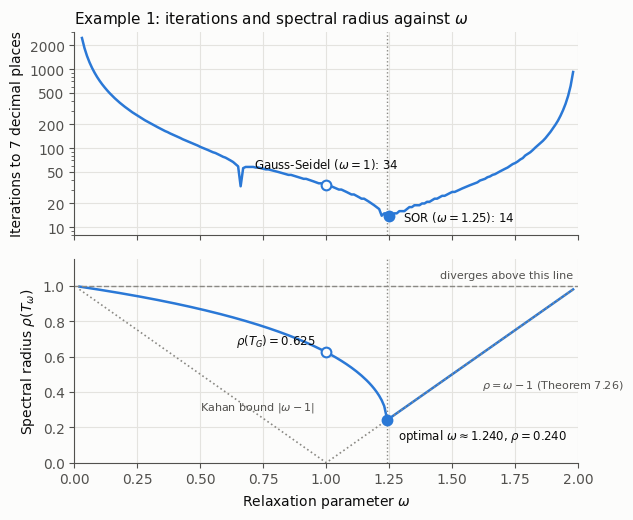

In [14]:
w_opt = optimal_omega(EX1.A)
rho_ex1 = RHO["Example 1"]
iters = np.array([np.nan if n is None else n for n in EX1_ITERS])

fig, (top, bottom) = plt.subplots(2, 1, figsize=(6.5, 5.6), sharex=True, gridspec_kw={"hspace": 0.12})

top.plot(OMEGAS, iters, color=BLUE)
top.set_yscale("log")
top.set_yticks([10, 20, 50, 100, 200, 500, 1000, 2000])
top.set_yticklabels(["10", "20", "50", "100", "200", "500", "1000", "2000"])
top.set_ylim(8, 3000)
top.set_ylabel("Iterations to 7 decimal places")
top.axvline(w_opt, color=REFERENCE, linestyle=":", linewidth=1)
mark(top, 1.0, iterations_needed(EX1, 1.0), "Gauss-Seidel ($\\omega = 1$): 34", 0, 12, filled=False, ha="center")
mark(top, 1.25, iterations_needed(EX1, 1.25), "SOR ($\\omega = 1.25$): 14", 10, -4)
top.set_title(r"Example 1: iterations and spectral radius against $\omega$", loc="left")

bottom.plot(OMEGAS, rho_ex1, color=BLUE)
reference_lines(bottom)
bottom.axvline(w_opt, color=REFERENCE, linestyle=":", linewidth=1)
mark(bottom, 1.0, spectral_radius(sor_matrix(EX1.A, 1.0)), r"$\rho(T_G) = 0.625$", -8, 6, filled=False, ha="right")
mark(bottom, w_opt, w_opt - 1, rf"optimal $\omega \approx {w_opt:.3f}$, $\rho = {w_opt - 1:.3f}$", 8, -14)
bottom.text(1.62, 0.42, r"$\rho = \omega - 1$ (Theorem 7.26)", color=INK_2, fontsize=8)
bottom.set_ylim(0, 1.15)
bottom.set_xlim(0, 2)
bottom.set_ylabel(r"Spectral radius $\rho(T_\omega)$")
bottom.set_xlabel(r"Relaxation parameter $\omega$")

fig.savefig("figures/fig1_example1_omega.pdf")
plt.show()

### Figure 2: Homework 3 systems

Each panel shows $\rho(T_\omega)$ for one Homework 3 system. SOR converges wherever the curve is below the
dashed line. The hollow marker is Gauss-Seidel ($\omega = 1$); the filled marker is the best $\omega$.

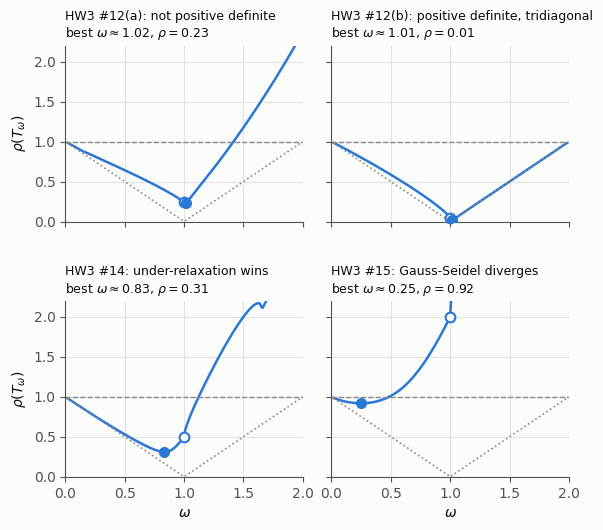

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(6.5, 5.6), sharex=True, sharey=True,
                         gridspec_kw={"hspace": 0.45, "wspace": 0.12})

notes = {
    "HW3 #12(a)": "not positive definite",
    "HW3 #12(b)": "positive definite, tridiagonal",
    "HW3 #14": "under-relaxation wins",
    "HW3 #15": "Gauss-Seidel diverges",
}
for ax, s, row in zip(axes.flat, HW3, SUMMARY[1:]):
    rho = RHO[s.name]
    ax.plot(OMEGAS, rho, color=BLUE)  # values above the axis limit run off the top of the panel
    reference_lines(ax, label=False)
    ax.plot(1.0, rho[OMEGAS == 1.0][0], "o", markersize=7, color=SURFACE,
            markeredgecolor=BLUE, markeredgewidth=1.5, zorder=3, clip_on=False)
    ax.plot(row["w_best"], row["rho_best"], "o", markersize=7, color=BLUE, zorder=3)
    ax.set_title(f"{s.name}: {notes[s.name]}\n"
                 rf"best $\omega \approx {row['w_best']:.2f}$, $\rho = {row['rho_best']:.2f}$",
                 loc="left", fontsize=9)
    ax.set_xlim(0, 2)
    ax.set_ylim(0, 2.2)

for ax in axes[1]:
    ax.set_xlabel(r"$\omega$")
for ax in axes[:, 0]:
    ax.set_ylabel(r"$\rho(T_\omega)$")

fig.savefig("figures/fig2_hw3_spectral_radius.pdf")
plt.show()

### Figure 3: Example 1, Jacobi vs. Gauss-Seidel vs. SOR

Error $\|\mathbf{x}^{(k)} - \mathbf{x}\|_\infty$ at each iteration, on a log scale. Each line is close to straight
with slope $\log_{10}\rho(T)$, which is why a smaller spectral radius means fewer iterations.

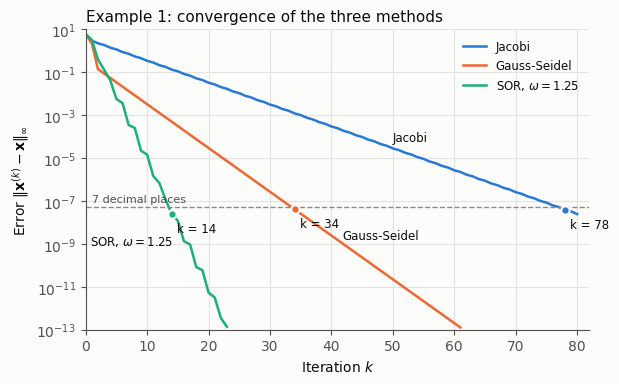

In [16]:
K = 80
with contextlib.redirect_stdout(io.StringIO()):  # tol = 0 runs all K iterations; Step 7's message is expected
    runs = [
        ("Jacobi", BLUE, jacobi(EX1.A, EX1.b, EX1.x0, tol=0, max_iter=K)),
        ("Gauss-Seidel", ORANGE, sor(EX1.A, EX1.b, EX1.x0, omega=1.0, tol=0, max_iter=K)),
        (r"SOR, $\omega = 1.25$", AQUA, sor(EX1.A, EX1.b, EX1.x0, omega=1.25, tol=0, max_iter=K)),
    ]

# Where each line's name sits: (iteration, offset in points, horizontal alignment)
name_spots = {"Jacobi": (50, (0, 8), "left"),
              "Gauss-Seidel": (40, (8, 0), "left"),
              r"SOR, $\omega = 1.25$": (16, (-8, 0), "right")}

fig, ax = plt.subplots(figsize=(6.5, 3.9))
for label, color, result in runs:
    errors = np.array([np.linalg.norm(x - EX1.exact, np.inf) for x in result.history])
    shown = errors > 1e-13  # below this the error is only round-off
    ax.plot(np.arange(len(errors))[shown], errors[shown], color=color, label=label)

    k_name, offset, ha = name_spots[label]
    ax.annotate(label, (k_name, errors[k_name]), xytext=offset, textcoords="offset points",
                fontsize=8.5, color=INK, ha=ha, va="center")

    n = first_accurate(result.history, EX1.exact)
    ax.plot(n, errors[n], "o", markersize=6, color=color, markeredgecolor=SURFACE, markeredgewidth=1.5, zorder=3)
    ax.annotate(f"k = {n}", (n, errors[n]), xytext=(4, -13), textcoords="offset points", fontsize=8.5, color=INK)

ax.axhline(0.5e-7, color=REFERENCE, linestyle="--", linewidth=1)
ax.text(1, 0.5e-7 * 1.8, "7 decimal places", color=INK_2, fontsize=8)
ax.set_yscale("log")
ax.set_ylim(1e-13, 10)
ax.set_xlim(0, K + 2)
ax.set_xticks(range(0, K + 1, 10))
ax.set_xlabel("Iteration $k$")
ax.set_ylabel(r"Error $\|\mathbf{x}^{(k)} - \mathbf{x}\|_\infty$")
ax.set_title("Example 1: convergence of the three methods", loc="left")
ax.legend(loc="upper right", frameon=False, fontsize=8.5)

fig.savefig("figures/fig3_example1_methods.pdf")
plt.show()